In [60]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist

In [61]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

In [62]:
print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


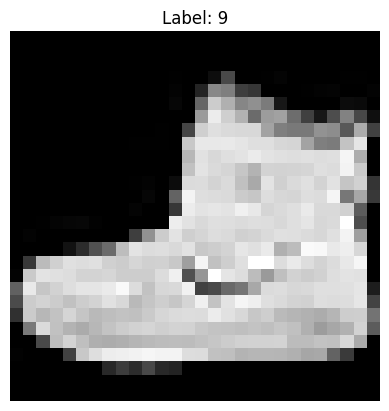

In [63]:
plt.imshow(X_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

In [64]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

In [65]:
X = X_train[:10000]
y = y_train[:10000]


In [66]:
X = X.reshape(X.shape[0], -1)

In [67]:
print(X.shape)

(10000, 784)


In [68]:
X = X / 255.0

In [69]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [70]:
X_pca.shape

(10000, 2)

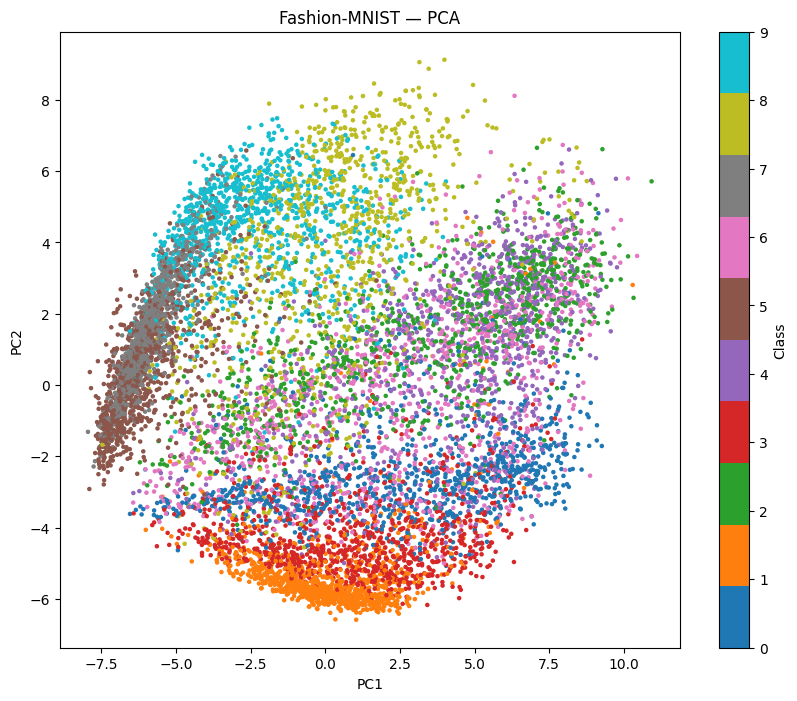

In [86]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    s=5,
    cmap="tab10"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Fashion-MNIST — PCA")
plt.colorbar(scatter, ticks=range(10), label="Class")

plt.show()

In [72]:
print(pca.explained_variance_ratio_)

[0.29056813 0.18012634]


In [73]:
pca = PCA(n_components=0.90)
X_pca = pca.fit_transform(X)

print(pca.n_components_)

82


In [74]:
print("Explained variance:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())
print("Components:", pca.components_.shape)


Explained variance: [0.29056813 0.18012634 0.05959236 0.04945724 0.03843161 0.03366369
 0.02311842 0.01928326 0.01364702 0.01324515 0.0101035  0.00909461
 0.00758434 0.0065381  0.00613137 0.00600305 0.00540722 0.00518959
 0.0046045  0.00457409 0.00435933 0.00414853 0.00389132 0.00374365
 0.00370819 0.00346224 0.00333531 0.00321052 0.00308838 0.00286822
 0.00275989 0.00264268 0.00258894 0.00250196 0.00247385 0.00233678
 0.00229245 0.00225107 0.00216139 0.00210463 0.00198863 0.00198086
 0.00194511 0.00183323 0.00179322 0.00171787 0.00165094 0.00164543
 0.00160624 0.00154342 0.00151876 0.00151298 0.00149198 0.00144112
 0.00142586 0.00136659 0.00134854 0.00131007 0.00127525 0.00126038
 0.00124246 0.0012159  0.00119781 0.0011506  0.00114824 0.00112264
 0.00111136 0.00109093 0.00106454 0.00103285 0.00101928 0.001008
 0.00099536 0.00095237 0.00094174 0.00094002 0.00092934 0.00092521
 0.00088382 0.00086944 0.00085658 0.00084511]
Total explained variance: 0.9004929997488679
Components: (82, 784

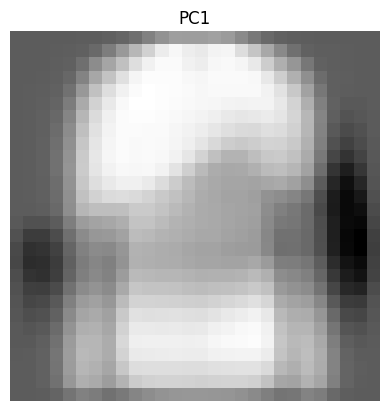

In [75]:
pc1 = pca.components_[0].reshape(28, 28)

plt.imshow(pc1, cmap="gray")
plt.title("PC1")
plt.axis("off")
plt.show()

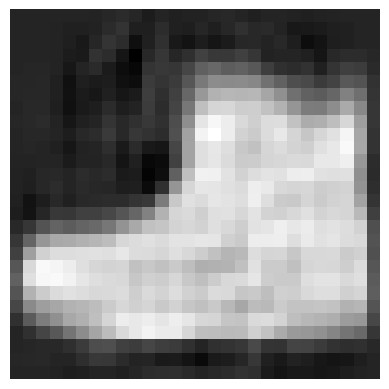

In [83]:
reconstructed = (
    X_pca[0, :82] @ pca.components_[:82]
    + pca.mean_
)
reconstructed = reconstructed.reshape(28, 28)
plt.imshow(reconstructed, cmap="gray")
plt.axis("off")
plt.show()

In [87]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2)

X_lda = lda.fit_transform(X, y)

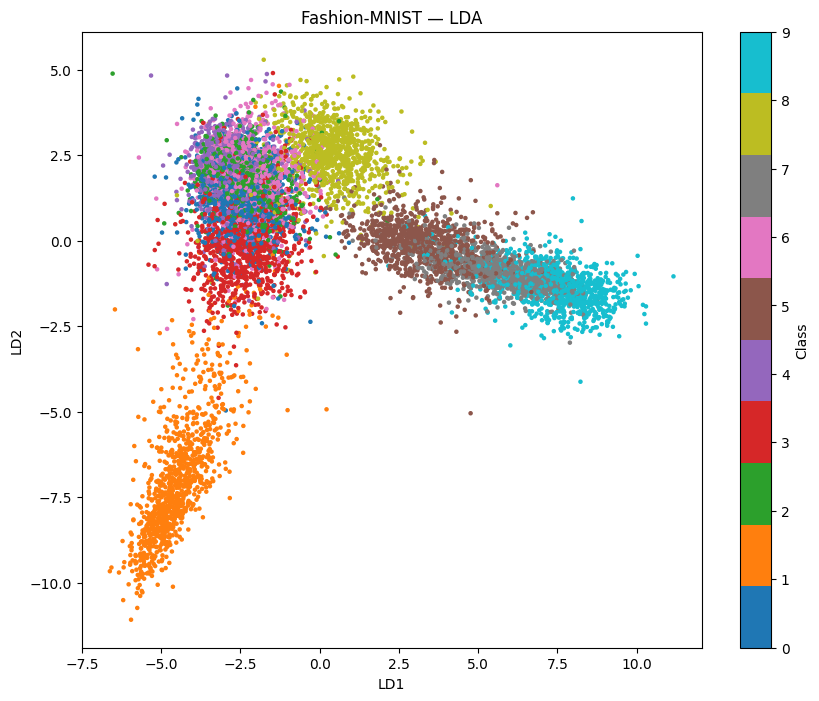

In [88]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    X_lda[:, 0],
    X_lda[:, 1],
    c=y,
    s=5,
    cmap="tab10"
)

plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("Fashion-MNIST — LDA")
plt.colorbar(scatter, ticks=range(10), label="Class")

plt.show()

In [89]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    random_state=42
)

X_tsne = tsne.fit_transform(X)

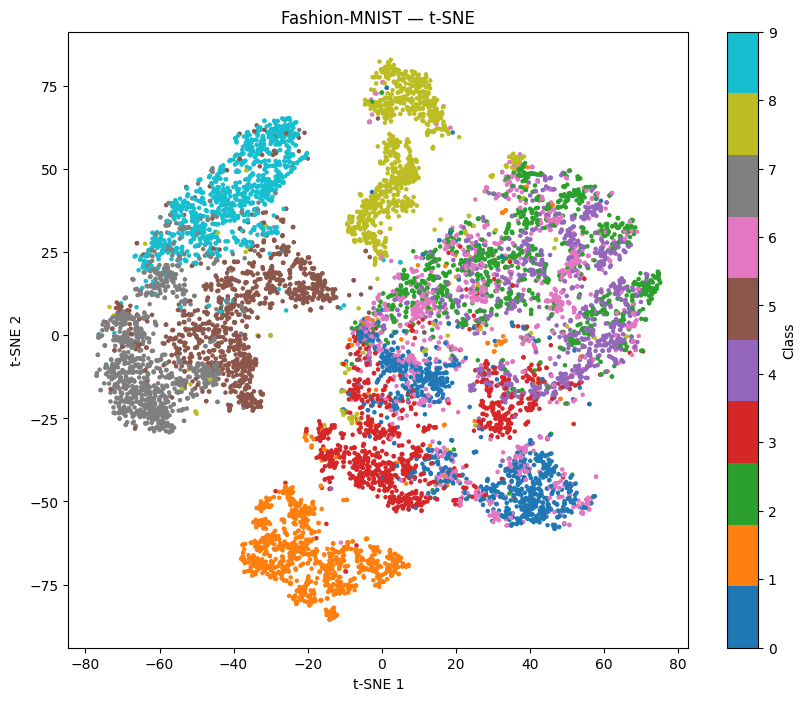

In [90]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y,
    s=5,
    cmap="tab10"
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Fashion-MNIST — t-SNE")
plt.colorbar(scatter, ticks=range(10), label="Class")

plt.show()

In [91]:
import umap

reducer = umap.UMAP(
    n_components=2,
    random_state=42
)

X_umap = reducer.fit_transform(X)

c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


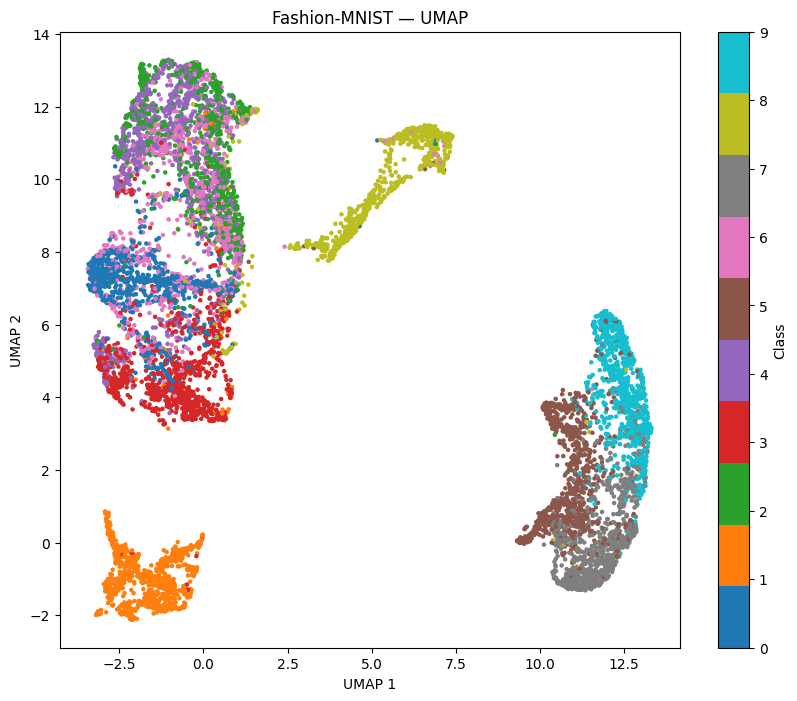

In [92]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=y,
    s=5,
    cmap="tab10"
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("Fashion-MNIST — UMAP")
plt.colorbar(scatter, ticks=range(10), label="Class")

plt.show()